# 07 - Explainability / Why-Cards (RQ2)

Uses your trained `model23/video_model.pth`. Produces **Grad-CAM why-cards**: for each shot, a heatmap showing *which region of the frame* the model used to decide, alongside the predicted label, confidence, and a one-line rule.

This answers RQ2 (cues -> tactical hints, explained): transparent per-event explanations. Saves the figure to `model23`.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. Runtime > Change runtime type > L4 GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless gdown

GPU: NVIDIA L4
Drive ready: True


In [2]:
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
VIDEO_CKPT  = MODELS + '/video_model.pth'
GDRIVE_FILE_ID = ''
EXTRACT_DIR = '/content/data'

NUM_FRAMES = 16
IMG        = 224
SEED       = 42
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

WHY = {
    'Short Serve': 'low contact near the net, short forward push',
    'Lift':        'underarm lift sending the shuttle high to the rear court',
    'Clear':       'overhead/flat hit driving the shuttle to the back court',
    'Drop Shot':   'soft downward touch landing just over the net',
    'Smash':       'steep, powerful overhead downward attack',
}

import os
print('Video model:', VIDEO_CKPT, '-> exists:', os.path.exists(VIDEO_CKPT))

Video model: /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth -> exists: True


In [3]:
import os, glob, zipfile, shutil
import cv2, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None
root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = [z for p in (DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip') for z in glob.glob(p)]
    zips = [z for z in zips if os.path.exists(z)]
    if not zips:
        import gdown
        outp = '/content/DATASET2.zip'
        if not os.path.exists(outp):
            gdown.download(id=GDRIVE_FILE_ID, output=outp, quiet=False)
        if os.path.exists(outp) and os.path.getsize(outp) > 1000000:
            zips = [outp]
    if zips:
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z: z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
DATASET_DIR = root or EXTRACT_DIR
print('DATASET_DIR =', DATASET_DIR)

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        base = models.resnet18(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b*t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def load_frames(path, n=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames')
    frames = []
    for i in np.linspace(0, total-1, n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < n: frames.append(frames[-1].copy() if frames else np.zeros((IMG,IMG,3),np.uint8))
    return frames[:n]
def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size/h, size/w); nh, nw = int(h*s), int(w*s)
    r = cv2.resize(img, (nw, nh)); c = np.zeros((size,size,3),np.uint8); y, x = (size-nh)//2, (size-nw)//2; c[y:y+nh, x:x+nw] = r; return c
def build_index(rootdir):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(rootdir, folder)
        if not os.path.isdir(p): continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'group_id': gid})
    return pd.DataFrame(rows)
def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val+test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtmp = df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test/(val+test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return df.iloc[tr].reset_index(drop=True), dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)

model = TemporalPoolingResNet().to(DEVICE)
ck = torch.load(VIDEO_CKPT, map_location=DEVICE)
model.load_state_dict(ck['model_state_dict'] if isinstance(ck, dict) and 'model_state_dict' in ck else ck)
model.eval()
TARGET_LAYER = model.features[7]
print('model loaded; target layer set to features[7] (layer4)')

DATASET_DIR = /content/data
model loaded; target layer set to features[7] (layer4)


In [4]:
def grad_cam_clip(path):
    frames = load_frames(path)
    lb = [letterbox(f) for f in frames]
    x = torch.stack([_norm(torch.from_numpy(f.astype(np.float32)/255.0).permute(2,0,1)) for f in lb]).unsqueeze(0).to(DEVICE)
    store = {}
    def fhook(m, i, o):
        store['act'] = o
        o.register_hook(lambda g: store.update(grad=g))
    h = TARGET_LAYER.register_forward_hook(fhook)
    model.zero_grad()
    logits = model(x)
    probs = torch.softmax(logits, dim=1)[0]
    pred = int(probs.argmax()); conf = float(probs[pred])
    logits[0, pred].backward()
    h.remove()
    A = store['act']
    G = store['grad']
    w = G.mean(dim=(2,3), keepdim=True)
    cam = torch.relu((w * A).sum(dim=1)).detach().cpu().numpy()
    t = int(cam.reshape(cam.shape[0], -1).sum(1).argmax())
    heat = cv2.resize(cam[t], (IMG, IMG))
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
    hc = cv2.cvtColor(cv2.applyColorMap((heat*255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    overlay = (0.55*lb[t] + 0.45*hc).astype(np.uint8)
    return lb[t], overlay, pred, conf

print('grad_cam_clip ready')

grad_cam_clip ready


/tmp/ipykernel_56108/2198009352.py:14: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  pred = int(probs.argmax()); conf = float(probs[pred])


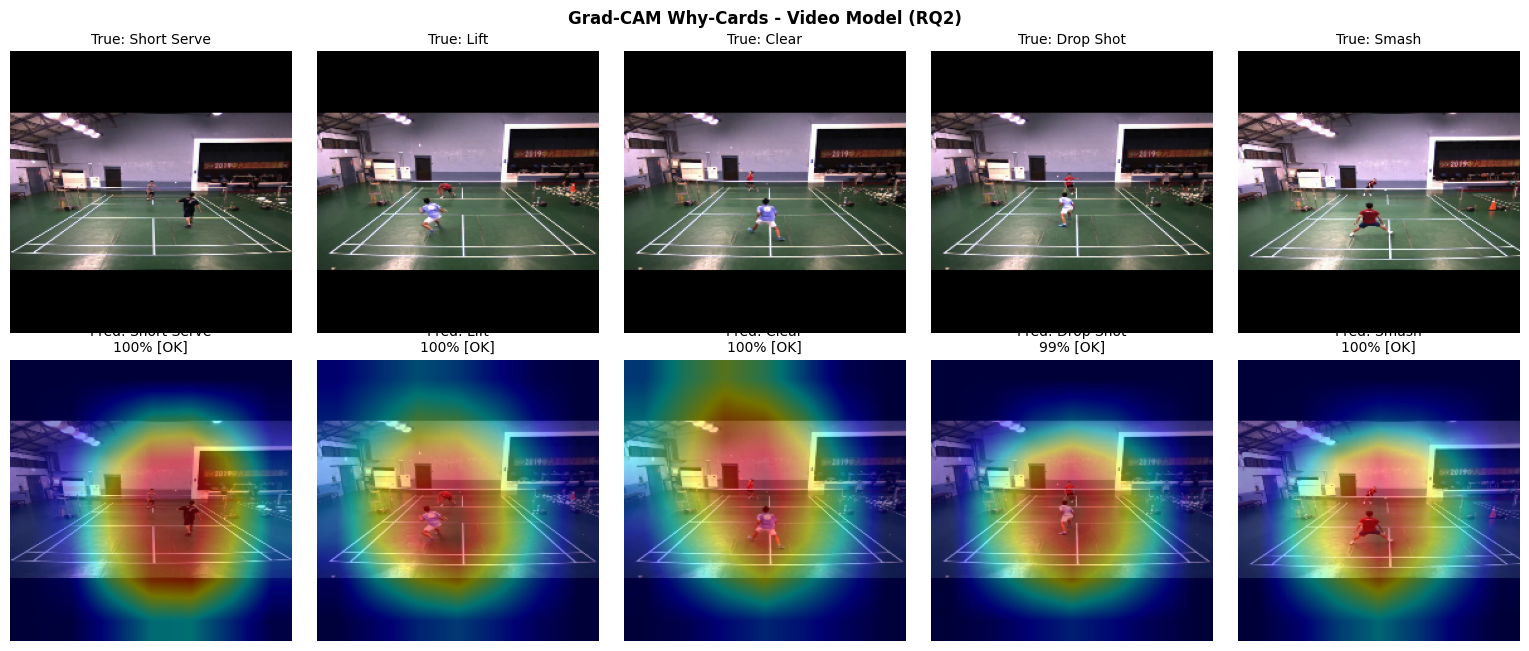

One-line rule shown to the coach per shot:
  Short Serve  : low contact near the net, short forward push
  Lift         : underarm lift sending the shuttle high to the rear court
  Clear        : overhead/flat hit driving the shuttle to the back court
  Drop Shot    : soft downward touch landing just over the net
  Smash        : steep, powerful overhead downward attack

Saved why-card figure to /content/drive/MyDrive/BadmintonFYP/model23/xai_why_cards.png


In [5]:
_, _, df_test = group_split(build_index(DATASET_DIR))
picks = []
for cid in range(NUM_CLASSES):
    sub = df_test[df_test.label_id == cid]
    if len(sub): picks.append((cid, sub.iloc[0].file_path))

n = len(picks)
fig, axes = plt.subplots(2, n, figsize=(3.1*n, 6.6))
for j, (cid, path) in enumerate(picks):
    orig, overlay, pred, conf = grad_cam_clip(path)
    axes[0, j].imshow(orig); axes[0, j].axis('off')
    axes[0, j].set_title('True: ' + ID_TO_NAME[cid], fontsize=10)
    axes[1, j].imshow(overlay); axes[1, j].axis('off')
    mark = 'OK' if pred == cid else 'X'
    axes[1, j].set_title('Pred: %s\n%.0f%% [%s]' % (ID_TO_NAME[pred], 100*conf, mark), fontsize=10)
plt.suptitle('Grad-CAM Why-Cards - Video Model (RQ2)', fontweight='bold')
plt.tight_layout(); plt.savefig(MODELS + '/xai_why_cards.png', dpi=150); plt.show()

print('One-line rule shown to the coach per shot:')
for k, v in WHY.items():
    print('  %-12s : %s' % (k, v))
print('\nSaved why-card figure to', MODELS + '/xai_why_cards.png')

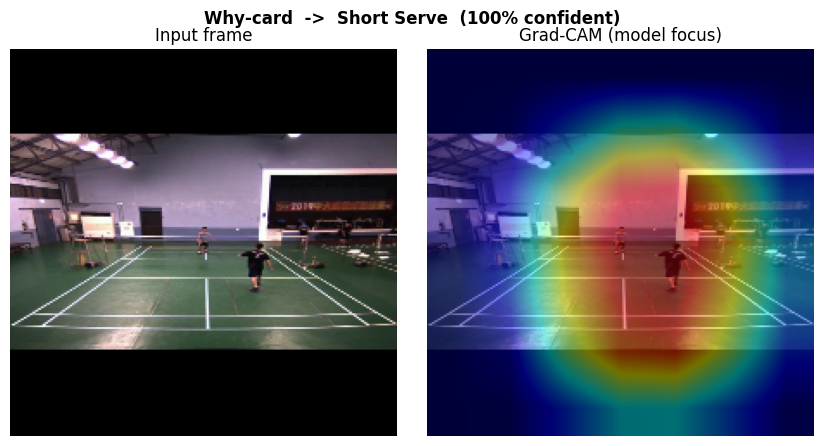

Shot     : Short Serve (100.0% confidence)
Why-card : low contact near the net, short forward push


In [6]:
SINGLE = df_test.iloc[0].file_path
orig, overlay, pred, conf = grad_cam_clip(SINGLE)
label = ID_TO_NAME[pred]

fig, ax = plt.subplots(1, 2, figsize=(8.5, 4.5))
ax[0].imshow(orig); ax[0].axis('off'); ax[0].set_title('Input frame')
ax[1].imshow(overlay); ax[1].axis('off'); ax[1].set_title('Grad-CAM (model focus)')
plt.suptitle('Why-card  ->  %s  (%.0f%% confident)' % (label, 100*conf), fontweight='bold')
plt.tight_layout(); plt.savefig(MODELS + '/xai_single_card.png', dpi=150); plt.show()
print('Shot     :', label, '(%.1f%% confidence)' % (100*conf))
print('Why-card :', WHY[label])